In [23]:
import pandas as pd

raw = pd.read_csv("/diabetic_data.csv", low_memory=False)

n_rows, n_cols = raw.shape
visits_per_patient = raw["patient_nbr"].value_counts()

print(f"Rows: {n_rows:,} | Columns: {n_cols}")
print(f"Unique patients: {len(visits_per_patient):,}")
print(f"Most encounters for one patient: {visits_per_patient.max()}")

print("\nReadmitted (count and %):")
print(
    raw["readmitted"]
    .value_counts()
    .to_frame("count")
    .assign(percent=lambda d: (d["count"] / n_rows * 100).round(1))
)

raw.head()

Rows: 101,766 | Columns: 50
Unique patients: 71,518
Most encounters for one patient: 40

Readmitted (count and %):
            count  percent
readmitted                
NO          54864     53.9
>30         35545     34.9
<30         11357     11.2


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [24]:
import csv
import pandas as pd


def load_id_mapping(path):
    """Split IDS_mapping.csv (three tables stacked in one file,
    separated by blank rows) into a dict of DataFrames."""
    tables, name = {}, None
    with open(path, newline="") as f:
        for row in csv.reader(f):
            if not row or not row[0].strip():      # blank row = end of a table
                name = None
            elif name is None:                     # header row = start of a table
                name = row[0].strip()
                tables[name] = []
            else:
                tables[name].append((int(row[0]), row[1].strip()))
    return {
        name: pd.DataFrame(rows, columns=[name, "description"])
        for name, rows in tables.items()
    }


ids = load_id_mapping("/IDS_mapping.csv")
for name, table in ids.items():
    print(f"{name}: {len(table)} codes")

print("\nDischarge codes:")
print(ids["discharge_disposition_id"].to_string(index=False))

admission_type_id: 8 codes
discharge_disposition_id: 30 codes
admission_source_id: 25 codes

Discharge codes:
 discharge_disposition_id                                                                                               description
                        1                                                                                        Discharged to home
                        2                                                     Discharged/transferred to another short term hospital
                        3                                                                             Discharged/transferred to SNF
                        4                                                                             Discharged/transferred to ICF
                        5                                      Discharged/transferred to another type of inpatient care institution
                        6                                                   Discharged/transferred

In [25]:
features = pd.read_csv("/diabetes_features.csv").dropna(how="all")
features

,Feature name,Type,Description and values
0,Encounter ID,Numeric,Unique identifier of an encounter
1,Patient number,Numeric,Unique identifier of a patient
2,Race,Nominal,"Values: Caucasian, Asian, African American, Hi..."
3,Gender,Nominal,"Values: male, female, and unknown/invalid"
4,Age,Nominal,"Grouped in 10-year intervals: [0, 10), [10, 20..."
5,Weight,Numeric,Weight in pounds.
6,Admission type,Nominal,Integer identifier corresponding to 9 distinct...
7,Discharge disposition,Nominal,Integer identifier corresponding to 29 distinc...
8,Admission source,Nominal,Integer identifier corresponding to 21 distinc...
9,Time in hospital,Numeric,Integer number of days between admission and d...


In [26]:
import pandas as pd

MED_COLUMNS = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone",
]


def load_raw(path):
    """Load the encounter data, treating '?' as missing.
    keep_default_na=False stops pandas from also turning the text 'None'
    (meaning 'test not taken') into a missing value."""
    return pd.read_csv(path, na_values=["?"], keep_default_na=False, low_memory=False)


df_raw = load_raw("/diabetic_data.csv")

miss = (df_raw.isna().mean() * 100).round(1)
print("Missing %:\n", miss[miss > 0].sort_values(ascending=False))

print("\nMedication columns in data:", len([c for c in MED_COLUMNS if c in df_raw]))

print("\nConstant columns:",
      [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) == 1])

print("\nA1Cresult values:\n", df_raw["A1Cresult"].value_counts(dropna=False))

Missing %:
 weight               96.9
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
dtype: float64

Medication columns in data: 23

Constant columns: ['examide', 'citoglipton']

A1Cresult values:
 A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


In [27]:
# Patients who died or went to hospice cannot be readmitted,
# so keeping them would dilute the readmission rate.
EXPIRED_OR_HOSPICE = [11, 13, 14, 19, 20, 21]


def build_cohort(df):
    """Drop expired/hospice discharges and add the binary target:
    1 = readmitted within 30 days, 0 = otherwise."""
    cohort = df[~df["discharge_disposition_id"].isin(EXPIRED_OR_HOSPICE)].copy()
    cohort["target"] = (cohort["readmitted"] == "<30").astype(int)
    return cohort


cohort = build_cohort(df_raw)

print("Removed (expired or hospice):", len(df_raw) - len(cohort))
print("Cohort size:", len(cohort))
print(f"30-day readmission rate: {cohort['target'].mean() * 100:.1f}%")

Removed (expired or hospice): 2423
Cohort size: 99343
30-day readmission rate: 11.4%


In [28]:
import os
import matplotlib.pyplot as plt

FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

DISCHARGE_LABELS = {
    1: "Home", 2: "Short-term hospital", 3: "Skilled nursing facility",
    5: "Other inpatient care", 6: "Home with home health",
    18: "Not recorded", 22: "Rehab facility",
}


def rate_chart(groups, title, xlabel, filename, horizontal=False):
    """Bar chart of the 30-day readmission rate for each group."""
    stats = cohort.groupby(groups)["target"].agg(rate="mean", n="size")
    stats["rate"] *= 100
    if horizontal:
        stats = stats.sort_values("rate")
    overall = cohort["target"].mean() * 100
    labels = stats.index.astype(str)

    fig, ax = plt.subplots(figsize=(9, 5))
    if horizontal:
        bars = ax.barh(labels, stats["rate"], color="#2a78d6", height=0.6)
        ax.axvline(overall, color="#6b7280", linestyle="--", linewidth=1)
        ax.set_xlabel("Readmitted within 30 days (%)")
        ax.set_ylabel(xlabel)
        bar_text = [f"{r:.1f}%  (n={n:,})" for r, n in zip(stats["rate"], stats["n"])]
    else:
        bars = ax.bar(labels, stats["rate"], color="#2a78d6", width=0.6)
        ax.axhline(overall, color="#6b7280", linestyle="--", linewidth=1)
        ax.set_ylabel("Readmitted within 30 days (%)")
        ax.set_xlabel(xlabel)
        bar_text = [f"{r:.1f}%" for r in stats["rate"]]

    ax.bar_label(bars, labels=bar_text, padding=3, fontsize=9, color="#374151")
    ax.set_title(f"{title}\n(dashed line = overall rate, {overall:.1f}%)", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(x=0.25 if horizontal else 0.02, y=0.02 if horizontal else 0.12)
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{filename}", dpi=150)
    plt.close(fig)


# 1. Prior inpatient visits (5 or more grouped together)
prior = cohort["number_inpatient"].clip(upper=5).map(lambda v: "5+" if v == 5 else str(v))
rate_chart(prior, "30-day readmission rate by prior inpatient visits",
           "Inpatient visits in the previous year", "readmit_by_prior_inpatient.png")

# 2. Discharge destination (7 most common)
top = cohort["discharge_disposition_id"].value_counts().head(7).index
disch = cohort.loc[cohort["discharge_disposition_id"].isin(top),
                   "discharge_disposition_id"].map(lambda i: DISCHARGE_LABELS.get(i, f"Code {i}"))
rate_chart(disch, "30-day readmission rate by discharge destination",
           "", "readmit_by_discharge.png", horizontal=True)

# 3. Age group
rate_chart(cohort["age"], "30-day readmission rate by age group",
           "Age group", "readmit_by_age.png")

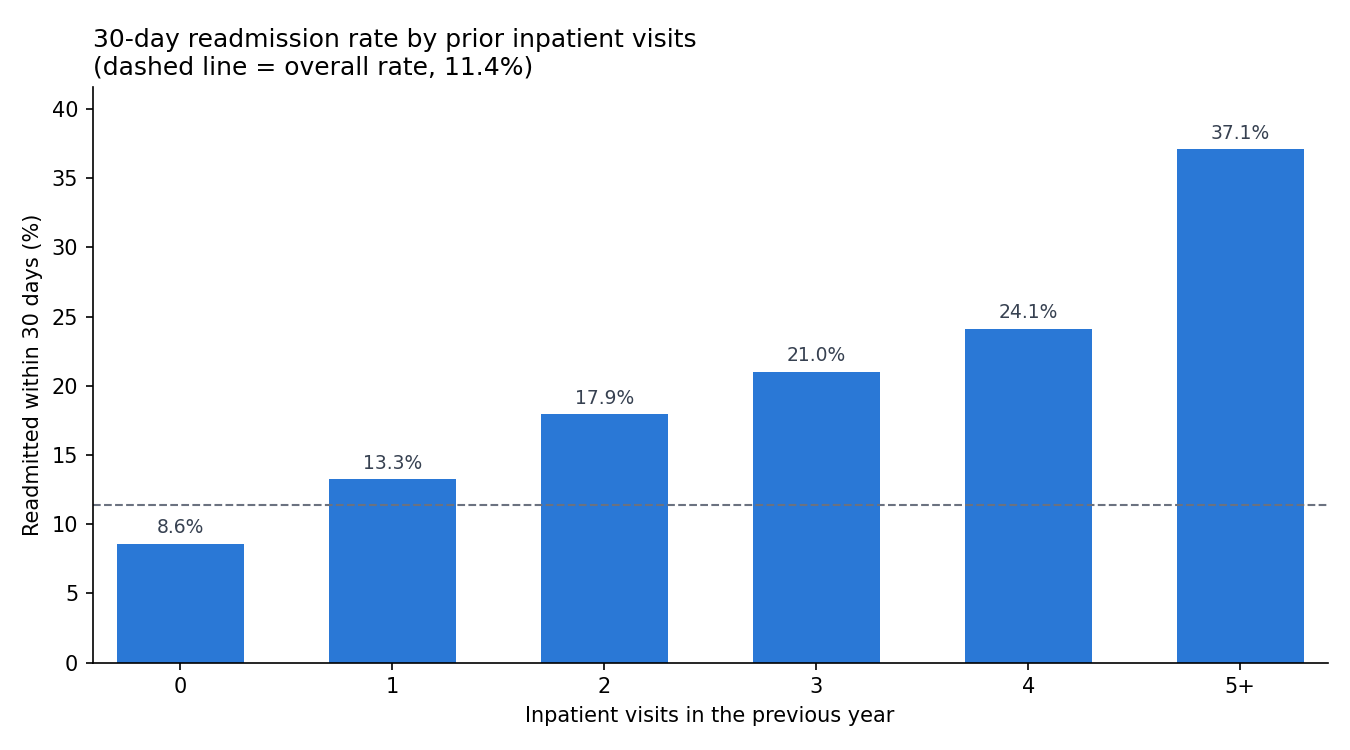

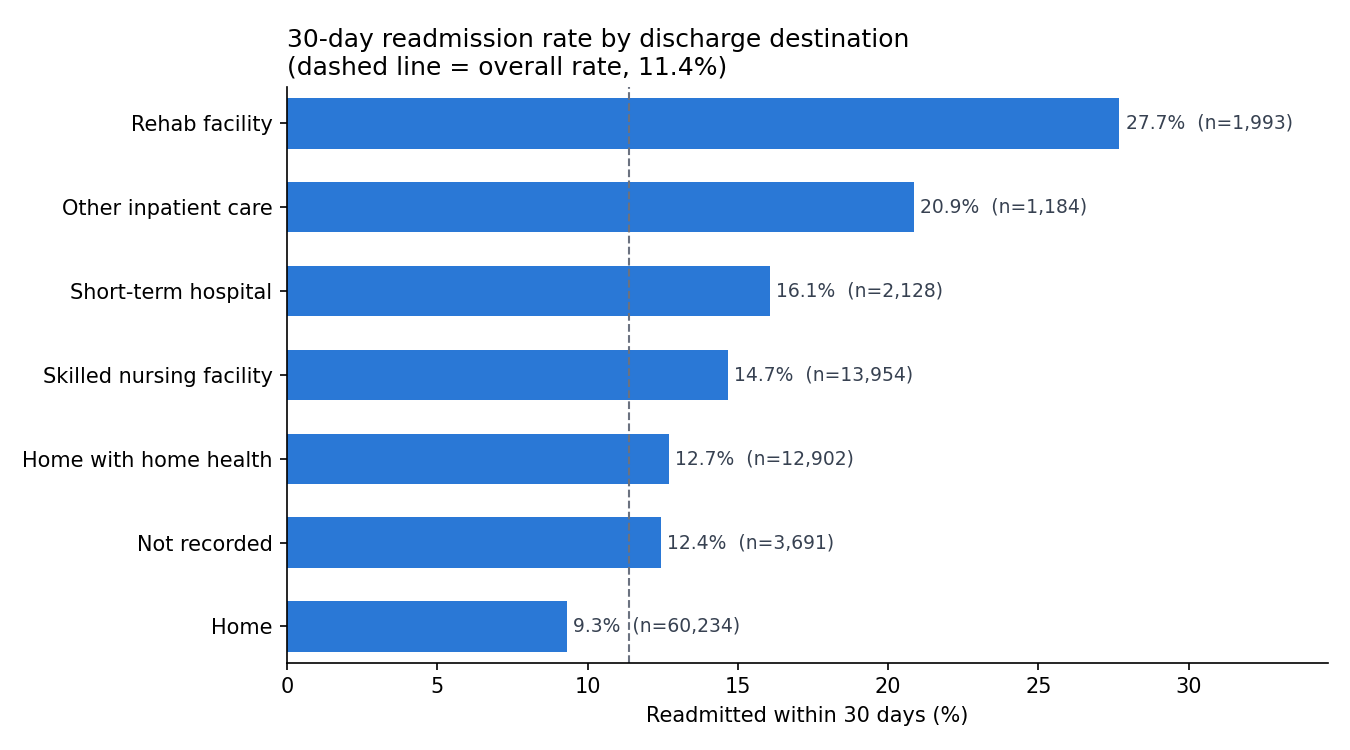

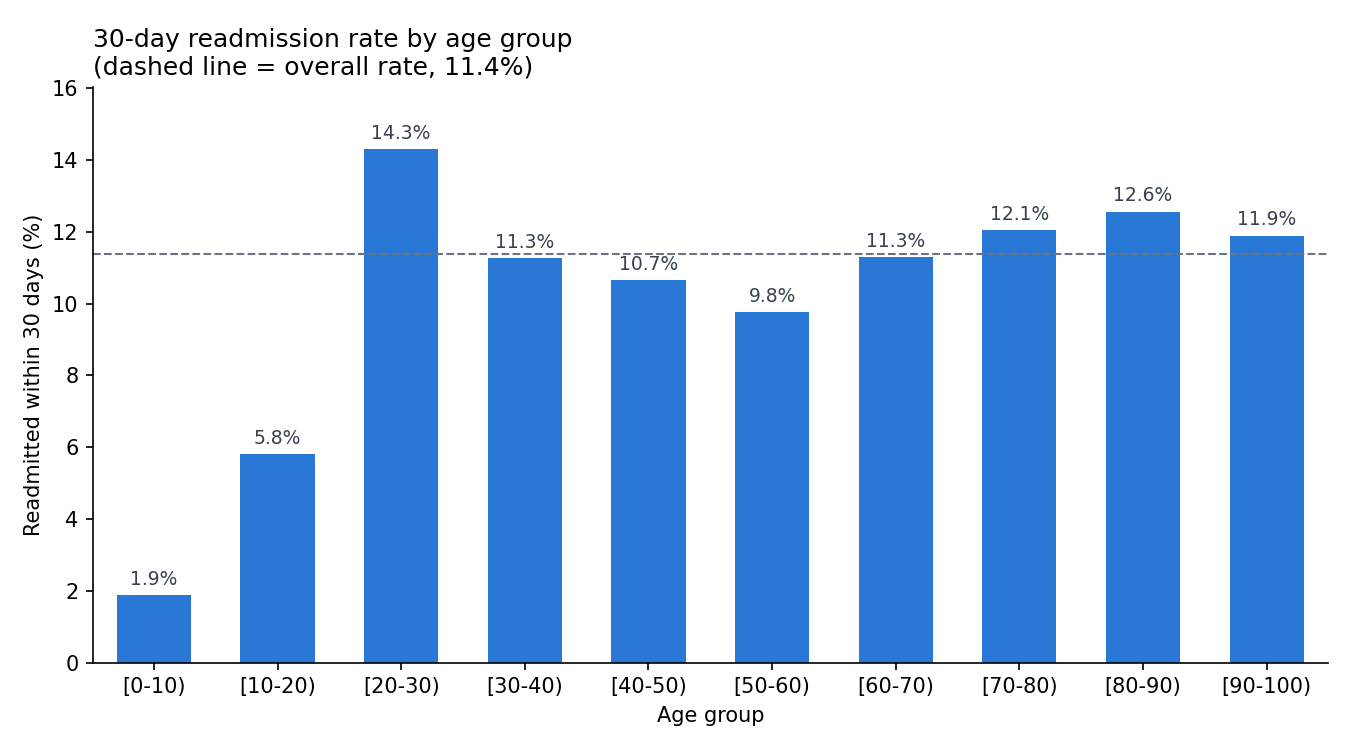

In [29]:
from IPython.display import Image, display

for f in ["readmit_by_prior_inpatient.png",
          "readmit_by_discharge.png",
          "readmit_by_age.png"]:
    display(Image(f"reports/figures/{f}", width=700))

In [30]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

DROP_COLUMNS = ["encounter_id", "patient_nbr", "weight", "payer_code",
                "examide", "citoglipton", "readmitted", "target"]
ID_COLUMNS = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]


def split_by_patient(df, test_size=0.2, seed=42):
    """Train/test split that keeps all of a patient's encounters on one side."""
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    train_idx, test_idx = next(splitter.split(df, groups=df["patient_nbr"]))
    return df.iloc[train_idx].copy(), df.iloc[test_idx].copy()


def diagnosis_group(code):
    """Collapse an ICD-9 code into one of nine broad clinical groups."""
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith(("V", "E")):
        return "Other"
    num = float(code)
    if int(num) == 250:
        return "Diabetes"
    if 390 <= num <= 459 or num == 785:
        return "Circulatory"
    if 460 <= num <= 519 or num == 786:
        return "Respiratory"
    if 520 <= num <= 579 or num == 787:
        return "Digestive"
    if 800 <= num <= 999:
        return "Injury"
    if 710 <= num <= 739:
        return "Musculoskeletal"
    if 580 <= num <= 629 or num == 788:
        return "Genitourinary"
    if 140 <= num <= 239:
        return "Neoplasms"
    return "Other"


def engineer_features(df):
    """Turn cohort rows into model features (target and ID columns removed)."""
    X = df.drop(columns=DROP_COLUMNS, errors="ignore").copy()
    meds = [c for c in MED_COLUMNS if c in X]

    # Age band "[70-80)" -> midpoint 75
    X["age"] = X["age"].str.extract(r"\[(\d+)-")[0].astype(int) + 5

    # Fill missing categories so they become their own level
    X["race"] = X["race"].fillna("Unknown")
    X["medical_specialty"] = X["medical_specialty"].fillna("Missing")

    # ID codes are categories, not quantities
    X[ID_COLUMNS] = X[ID_COLUMNS].astype(str)

    # Hundreds of raw diagnosis codes -> nine broad groups
    for c in ["diag_1", "diag_2", "diag_3"]:
        X[c] = X[c].map(diagnosis_group)

    # Yes/no flags -> 1/0
    X["change"] = (X["change"] == "Ch").astype(int)
    X["diabetesMed"] = (X["diabetesMed"] == "Yes").astype(int)

    # New summary features
    X["total_prior_visits"] = (X["number_outpatient"] + X["number_emergency"]
                               + X["number_inpatient"])
    X["n_diabetes_meds"] = (X[meds] != "No").sum(axis=1)
    X["n_med_dose_changes"] = X[meds].isin(["Up", "Down"]).sum(axis=1)
    return X

In [31]:
train_full, test = split_by_patient(cohort)
overlap = set(train_full["patient_nbr"]) & set(test["patient_nbr"])

print("Train encounters:", len(train_full), "| Test encounters:", len(test))
print("Patients in both train and test:", len(overlap))

X_preview = engineer_features(cohort).head()
print("Number of model features:", X_preview.shape[1])
X_preview

Train encounters: 79541 | Test encounters: 19802
Patients in both train and test: 0
Number of model features: 46


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,...,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,total_prior_visits,n_diabetes_meds,n_med_dose_changes
0,Caucasian,Female,5,6,25,1,1,Pediatrics-Endocrinology,41,0,...,No,No,No,No,No,0,0,0,0,0
1,Caucasian,Female,15,1,1,7,3,Missing,59,0,...,No,No,No,No,No,1,1,0,1,1
2,AfricanAmerican,Female,25,1,1,7,2,Missing,11,5,...,No,No,No,No,No,0,1,3,1,0
3,Caucasian,Male,35,1,1,7,2,Missing,44,1,...,No,No,No,No,No,1,1,0,1,1
4,Caucasian,Male,45,1,1,7,1,Missing,51,0,...,No,No,No,No,No,1,1,0,2,0


MODELLING QUESTION : will this patient be readmitted within 30 days of discharge?


In [32]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Inner split: a validation set (by patient) used only to choose the model
train, val = split_by_patient(train_full, test_size=0.20, seed=42)

X_train, y_train = engineer_features(train), train["target"].values
X_val, y_val = engineer_features(val), val["target"].values
X_test, y_test = engineer_features(test), test["target"].values

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

print(f"Train: {len(X_train):,} | Validation: {len(X_val):,} | Test: {len(X_test):,}")
print(f"{len(num_cols)} numeric + {len(cat_cols)} categorical = {X_train.shape[1]} features")


def make_prep(scale):
    """Preprocessing: impute (and optionally scale) numbers, one-hot encode categories."""
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    cat_steps = [
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                 min_frequency=30, sparse_output=False)),
    ]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline(cat_steps), cat_cols),
    ])


models = {
    "Logistic regression": Pipeline([
        ("prep", make_prep(scale=True)),
        ("model", LogisticRegression(C=0.5, max_iter=3000)),
    ]),
    "Gradient boosting": Pipeline([
        ("prep", make_prep(scale=False)),
        ("model", HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=400, min_samples_leaf=50,
            l2_regularization=1.0, early_stopping=True, random_state=42)),
    ]),
}

val_pr = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_val)[:, 1]
    val_pr[name] = average_precision_score(y_val, p)
    print(f"{name:<20s} validation ROC AUC: {roc_auc_score(y_val, p):.3f} | "
          f"PR AUC: {val_pr[name]:.3f}")

gain = val_pr["Gradient boosting"] - val_pr["Logistic regression"]
best_name = "Gradient boosting" if gain > 0.01 else "Logistic regression"
best = models[best_name]
print(f"Boosting gain on validation PR AUC: {gain:+.4f} -> selected: {best_name}")

Train: 63,807 | Validation: 15,734 | Test: 19,802
14 numeric + 32 categorical = 46 features
Logistic regression  validation ROC AUC: 0.665 | PR AUC: 0.219
Gradient boosting    validation ROC AUC: 0.676 | PR AUC: 0.227
Boosting gain on validation PR AUC: +0.0084 -> selected: Logistic regression


Model: Logistic regression
Test ROC AUC: 0.664
Test PR AUC:  0.220  (base rate 0.112)
Brier score:  0.0951  (always predicting the base rate: 0.0994)

Flagging the top 20% by risk (score >= 0.143):
  Encounters flagged:     3,961 of 19,802
  Readmissions caught:    38.0% of all 30-day readmissions
  Readmission rate there: 21.3% vs 11.2% overall (lift 1.9x)


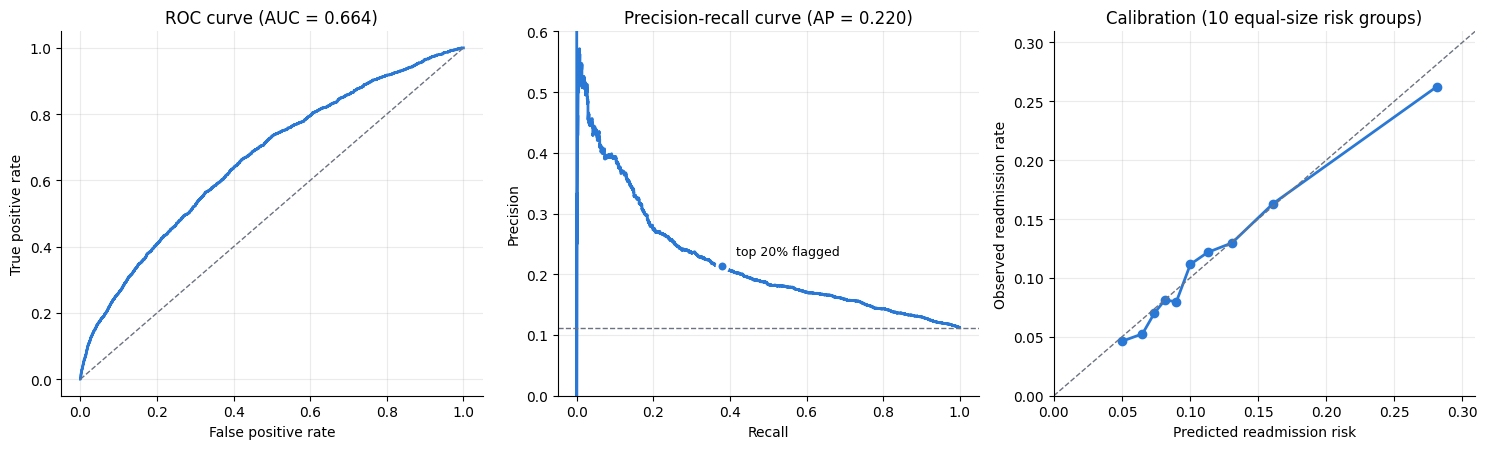

In [33]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, precision_recall_curve, brier_score_loss,
                             roc_auc_score, average_precision_score)
from sklearn.calibration import calibration_curve

# Final, one-time evaluation of the selected model on the held-out test set
p_test = best.predict_proba(X_test)[:, 1]
base_rate = y_test.mean()

print(f"Model: {best_name}")
print(f"Test ROC AUC: {roc_auc_score(y_test, p_test):.3f}")
print(f"Test PR AUC:  {average_precision_score(y_test, p_test):.3f}  (base rate {base_rate:.3f})")
print(f"Brier score:  {brier_score_loss(y_test, p_test):.4f}  "
      f"(always predicting the base rate: {base_rate * (1 - base_rate):.4f})")

# Operating point: flag the highest-risk 20% of encounters
top_frac = 0.20
threshold = np.quantile(p_test, 1 - top_frac)
flagged = p_test >= threshold
precision = y_test[flagged].mean()
recall = y_test[flagged].sum() / y_test.sum()

print(f"\nFlagging the top {top_frac:.0%} by risk (score >= {threshold:.3f}):")
print(f"  Encounters flagged:     {flagged.sum():,} of {len(y_test):,}")
print(f"  Readmissions caught:    {recall:.1%} of all 30-day readmissions")
print(f"  Readmission rate there: {precision:.1%} vs {base_rate:.1%} overall "
      f"(lift {precision / base_rate:.1f}x)")

# Curves
fpr, tpr, _ = roc_curve(y_test, p_test)
prec, rec, _ = precision_recall_curve(y_test, p_test)
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")

BLUE, GREY = "#2a78d6", "#6b7280"
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

axes[0].plot(fpr, tpr, color=BLUE, linewidth=2)
axes[0].plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1)
axes[0].set(title=f"ROC curve (AUC = {roc_auc_score(y_test, p_test):.3f})",
            xlabel="False positive rate", ylabel="True positive rate")

axes[1].plot(rec, prec, color=BLUE, linewidth=2)
axes[1].axhline(base_rate, color=GREY, linestyle="--", linewidth=1)
axes[1].scatter([recall], [precision], color=BLUE, s=60, zorder=3,
                edgecolor="white", linewidth=2)
axes[1].annotate(f"top {top_frac:.0%} flagged", (recall, precision),
                 xytext=(10, 8), textcoords="offset points", fontsize=9)
axes[1].set(title=f"Precision-recall curve (AP = {average_precision_score(y_test, p_test):.3f})",
            xlabel="Recall", ylabel="Precision", ylim=(0, 0.6))

lim = max(mean_pred.max(), frac_pos.max()) * 1.1
axes[2].plot(mean_pred, frac_pos, color=BLUE, linewidth=2, marker="o", markersize=6)
axes[2].plot([0, lim], [0, lim], color=GREY, linestyle="--", linewidth=1)
axes[2].set(title="Calibration (10 equal-size risk groups)",
            xlabel="Predicted readmission risk", ylabel="Observed readmission rate",
            xlim=(0, lim), ylim=(0, lim))

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.25)

fig.tight_layout()
os.makedirs("reports/figures", exist_ok=True)
fig.savefig("reports/figures/test_performance.png", dpi=150)
plt.show()

In [34]:
import pandas as pd
from sklearn.metrics import roc_auc_score

t = test.assign(p=p_test, flag=flagged)
t["no_prior"] = (t["number_inpatient"] + t["number_emergency"] + t["number_outpatient"]) == 0

readmits = t[t["target"] == 1]
caught, missed = readmits[readmits["flag"]], readmits[~readmits["flag"]]

print(f"Readmissions in test set: {len(readmits):,}")
print(f"  Caught (flagged): {len(caught):,} | Missed (not flagged): {len(missed):,}")
print(f"Average prior inpatient stays - caught: {caught['number_inpatient'].mean():.2f} | "
      f"missed: {missed['number_inpatient'].mean():.2f}")
print(f"Missed readmissions with no prior visits at all: {missed['no_prior'].mean():.1%}")
print(f"False alarms (flagged, not readmitted): {(t['flag'] & (t['target'] == 0)).sum():,} "
      f"of {t['flag'].sum():,} flagged")

# Performance by subgroup (groups with more than 300 encounters)
rows = []
for col in ["race", "gender", "age"]:
    for value, part in t.groupby(t[col].fillna("Missing")):
        if len(part) > 300:
            rows.append({
                "group": f"{col}: {value}",
                "n": len(part),
                "readmit_rate": part["target"].mean(),
                "roc_auc": roc_auc_score(part["target"], part["p"]),
                "pct_flagged": part["flag"].mean(),
            })

pd.DataFrame(rows).set_index("group").round(3)

Readmissions in test set: 2,216
  Caught (flagged): 843 | Missed (not flagged): 1,373
Average prior inpatient stays - caught: 2.66 | missed: 0.37
Missed readmissions with no prior visits at all: 57.2%
False alarms (flagged, not readmitted): 3,118 of 3,961 flagged


,n,readmit_rate,roc_auc,pct_flagged
group,,,,
race: AfricanAmerican,3707,0.107,0.661,0.204
race: Caucasian,14886,0.115,0.663,0.204
race: Hispanic,371,0.105,0.744,0.183
race: Missing,418,0.091,0.617,0.091
gender: Female,10645,0.112,0.672,0.211
gender: Male,9157,0.112,0.656,0.188
age: [20-30),388,0.155,0.868,0.232
age: [30-40),729,0.106,0.708,0.128
age: [40-50),1909,0.106,0.660,0.134


API DEMO


In [35]:
!pip install -q fastapi uvicorn

In [36]:
import os, threading, time
from typing import Any

import joblib
import pandas as pd
import requests
import uvicorn
from fastapi import FastAPI, HTTPException

# 1. Save the selected model, then load it back the way a real service would
os.makedirs("models", exist_ok=True)
joblib.dump({"model": best, "name": best_name, "threshold": float(threshold)},
            "models/readmission_model.joblib")
artifact = joblib.load("models/readmission_model.joblib")

# 2. Any field the caller leaves out is filled with a typical value
#    (median for numbers, most common value for categories), taken from training data
NOT_INPUTS = ["encounter_id", "patient_nbr", "weight", "payer_code",
              "examide", "citoglipton", "readmitted", "target"]
raw_fields = [c for c in train.columns if c not in NOT_INPUTS]
RAW_FIELD_DEFAULTS = {
    c: (int(train[c].median()) if pd.api.types.is_numeric_dtype(train[c])
        else train[c].mode()[0])
    for c in raw_fields
}

# 3. The API
app = FastAPI(title="30-day readmission risk API")


@app.get("/health")
def health():
    return {"status": "ok", "model": artifact["name"]}


@app.post("/predict")
def predict(encounter: dict[str, Any]):
    unknown = sorted(set(encounter) - set(RAW_FIELD_DEFAULTS))
    if unknown:
        raise HTTPException(status_code=422, detail=f"Unknown fields: {unknown}")
    try:
        row = pd.DataFrame([{**RAW_FIELD_DEFAULTS, **encounter}])
        prob = float(artifact["model"].predict_proba(engineer_features(row))[0, 1])
    except Exception as err:
        raise HTTPException(status_code=422, detail=f"Could not score encounter: {err}")
    return {
        "readmission_30d_probability": round(prob, 4),
        "high_risk_flag": prob >= artifact["threshold"],
        "threshold": round(artifact["threshold"], 4),
        "fields_defaulted": len(RAW_FIELD_DEFAULTS) - len(encounter),
    }


# 4. Run the server in a background thread so the notebook stays usable
PORT = 8000
server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=PORT, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start()
time.sleep(2)

# 5. Call it like a client would
URL = f"http://127.0.0.1:{PORT}"
print("Health:", requests.get(f"{URL}/health").json())

low_risk = {"age": "[50-60)", "time_in_hospital": 2, "number_inpatient": 0}
high_risk = {"age": "[70-80)", "time_in_hospital": 9, "number_inpatient": 4,
             "number_emergency": 2, "discharge_disposition_id": 22, "insulin": "Up"}

for label, payload in [("Low-risk example", low_risk), ("High-risk example", high_risk)]:
    print(f"{label}:", requests.post(f"{URL}/predict", json=payload).json())

bad = requests.post(f"{URL}/predict", json={"blood_pressure": 120})
print("Bad request:", bad.status_code, bad.json())

ERROR:    [Errno 98] error while attempting to bind on address ('127.0.0.1', 8000): address already in use


Health: {'status': 'ok', 'model': 'Logistic regression'}
Low-risk example: {'readmission_30d_probability': 0.0919, 'high_risk_flag': False, 'threshold': 0.1428, 'fields_defaulted': 40}
High-risk example: {'readmission_30d_probability': 0.5603, 'high_risk_flag': True, 'threshold': 0.1428, 'fields_defaulted': 37}
Bad request: 422 {'detail': "Unknown fields: ['blood_pressure']"}


ADDITIONAL BUSSINESS QUESTION

A. LENGTH OF STAY AT READMISSION : bed and staffing planning and cost
B. HbA1C Testing gap : only 17 % of diabetic encounters had HBA1C measured. find where testing is skipped , and compare readmission with propensity meetings.

C. HIGH UTILIZER SEGMENT A: patient level clustering (upto 40 encounters per patient) to target care management programms
